# Phase 2 — Exploratory Data Analysis & Insight Generation
**ITS 2122 — Python for Data Science & AI | Sem 3 2026**  
**Project:** Credit Risk & Customer Financial Health Analytics  

---

## Objectives

Answers the board's four core questions using the cleaned dataset from Phase 1:

1. **Default-Rate Profiling** — How does risk vary across demographics and credit-limit tiers?
2. **Repayment-Behaviour Analysis** — Which delay patterns are the strongest early-warning signals?
3. **Financial Position Analysis** — How do bills, payments and utilisation differ between defaulters and payers?
4. **Relationship Analysis** — What do correlations reveal about the drivers of default?

**≥ 8 visualisations** are produced, each with a title, labelled axes, and a written interpretation.


## Imports and Setup

In [1]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# ── Display settings ─────────────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ── Load cleaned dataset (output of Phase 1) ─────────────────────────
CLEANED_PATH = "cleaned_credit_data.csv"
df = pd.read_csv(CLEANED_PATH)

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols")
df.head(3)


Loaded: 30,000 rows × 34 cols


,customer_id,credit_limit,sex,education,marriage,age,pay_status_1,pay_status_2,pay_status_3,pay_status_4,pay_status_5,pay_status_6,bill_amount_1,bill_amount_2,bill_amount_3,...,pay_amount_2,pay_amount_3,pay_amount_4,pay_amount_5,pay_amount_6,default_next_month,flag_delay_no_bill,flag_over_limit,flag_credit_balance,avg_bill_amount,avg_pay_amount,pay_to_bill_ratio,num_delayed_months,max_delay_months,balance_trend
0,1,20000,Female,University,Married,24,2,2,-1,-1,-2,-2,3913,3102,689,...,689,0,0,0,0,1,0,0,0,"1,284.00",114.83,0.09,2,2,3913
1,2,120000,Female,University,Single,26,-1,2,0,0,0,2,2682,1725,2682,...,1000,1000,1000,0,2000,1,0,0,0,"2,846.17",833.33,0.29,2,2,-579
2,3,90000,Female,University,Single,34,0,0,0,0,0,0,29239,14027,13559,...,1500,1000,1000,1000,5000,0,0,0,0,"16,942.17","1,836.33",0.11,0,0,13690


## Constants and Derived Columns

All column groups, colours, and derived features are centralised here so that subsequent cells stay concise.

The cleaned CSV deliberately does not persist phase-specific reporting fields. This notebook recreates the canonical `age_group`, `credit_limit_tier`, and `credit_utilization` fields from saved Phase 1 columns; Phase 3 and Phase 4 reuse the same `credit_utilization` formula independently.

**Tiering choice:** `credit_limit_tier` uses `pd.qcut(..., q=4)` so the four EDA groups contain similar numbers of customers. This makes default-rate comparison more stable than arbitrary cut-offs, but the resulting boundaries are relative to this portfolio and are not proposed as production credit-policy thresholds. The notebook prints the exact TWD boundaries on every run.

In [2]:
# ── Column groups ────────────────────────────────────────────────────
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
TARGET = 'default_next_month'

# ── Colour scheme ────────────────────────────────────────────────────
# Consistent blue = payer, red = defaulter across all charts.
CLR_NON_DEFAULT = '#2171b5'
CLR_DEFAULT = '#cb181d'
CLR_PALETTE = [CLR_NON_DEFAULT, CLR_DEFAULT]
LABEL_MAP = {0: 'Non-Default', 1: 'Default'}

# ── Figure size presets ───────────────────────────────────────────────
FIG_SINGLE = (11, 5)
FIG_WIDE = (14, 5)

# ── Output folder for exported charts ────────────────────────────────
os.makedirs('figures', exist_ok=True)

# ── Readable label column ─────────────────────────────────────────────
df['default_label'] = df[TARGET].map(LABEL_MAP)

# ── Phase-specific reporting fields (recreated from cleaned CSV) ─────
# These are intentionally in-memory fields, not persisted in Phase 1.
# ── Age groups ───────────────────────────────────────────────────────
AGE_BINS = [0, 29, 39, 49, 59, 110]
AGE_LABELS = ['≤29', '30–39', '40–49', '50–59', '60+']
df['age_group'] = pd.cut(
    df['age'],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=True,
)

# ── Credit-limit tiers (equal-frequency via qcut) ─────────────────────
# pd.qcut divides into 4 equal-count groups so each tier represents
# 25% of the portfolio — avoiding arbitrary manual thresholds.
TIER_LABELS = ['Low', 'Medium', 'High', 'Very High']
df['credit_limit_tier'], _tier_bins = pd.qcut(
    df['credit_limit'],
    q=4,
    labels=TIER_LABELS,
    retbins=True,
    duplicates='drop',
)
print('Credit-limit tier boundaries (NTD):')

# Credit utilisation is shared with Phases 3-4. Negative average bills
# are credit balances, so they are clipped to zero lender exposure.
df['credit_utilization'] = (
    df['avg_bill_amount'] / df['credit_limit']
).clip(lower=0)

for label, lo, hi in zip(
    TIER_LABELS, _tier_bins[:-1], _tier_bins[1:]
):
    print(f'  {label:<10}: {lo:>8,.0f} – {hi:>9,.0f}')

# ── Baseline default rate used across all charts ──────────────────────
OVERALL_DR = df[TARGET].mean() * 100
print(f'\nOverall default rate : {OVERALL_DR:.2f}%')
print(f'Defaulters           : {df[TARGET].sum():,}')
print(f'Non-defaulters       : {(df[TARGET]==0).sum():,}')


Credit-limit tier boundaries (NTD):
  Low       :   10,000 –    50,000
  Medium    :   50,000 –   140,000
  High      :  140,000 –   240,000
  Very High :  240,000 – 1,000,000

Overall default rate : 22.12%
Defaulters           : 6,636
Non-defaulters       : 23,364


## Reusable Helper — `plot_default_rate`

Defined once, called for every categorical default-rate chart to keep subsequent cells concise and consistent.

In [3]:
def plot_default_rate(
    data: pd.DataFrame,
    group_col: str,
    title: str,
    xlabel: str,
    ax: plt.Axes,
    order: list = None,
    x_rotation: int = 0,
) -> None:
    """Bar chart of default rate (%) per category.

    Draws a dashed reference line at the portfolio-wide
    default rate and annotates each bar with its exact
    percentage value.

    Parameters
    ----------
    data : pd.DataFrame
        DataFrame with group_col and TARGET columns.
    group_col : str
        Categorical column to group by.
    title : str
        Chart title.
    xlabel : str
        X-axis label.
    ax : plt.Axes
        Axes object to draw on.
    order : list, optional
        Explicit category order for the x-axis.
    x_rotation : int
        X-tick label rotation in degrees.
    """
    rates = (
        data.groupby(group_col, observed=True)[TARGET]
        .mean()
        .mul(100)
        .reset_index(name='default_rate')
    )
    if order is not None:
        rates[group_col] = pd.Categorical(
            rates[group_col],
            categories=order,
            ordered=True,
        )
        rates = rates.sort_values(group_col)

    sns.barplot(
        data=rates,
        x=group_col,
        y='default_rate',
        hue=group_col,
        palette='RdYlGn_r',
        legend=False,
        order=order,
        ax=ax,
    )

    # Dashed reference: portfolio-wide default rate
    ax.axhline(
        OVERALL_DR,
        color='navy',
        linestyle='--',
        linewidth=1.4,
        label=f'Portfolio avg ({OVERALL_DR:.1f}%)',
    )

    # Value annotations above each bar
    for patch in ax.patches:
        h = patch.get_height()
        if np.isnan(h) or h == 0:
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            h + 0.35,
            f'{h:.1f}%',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold',
        )

    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Default Rate (%)', fontsize=11)
    ax.set_ylim(0, rates['default_rate'].max() * 1.25)
    ax.tick_params(axis='x', labelsize=9, rotation=x_rotation)
    ax.legend(fontsize=9)


print('Helper function defined ✓')


Helper function defined ✓


---
## Section 2.1 — Default-Rate Analysis

We begin with the portfolio baseline, then break default rates down by the four demographic and limit dimensions the board specifically requested.

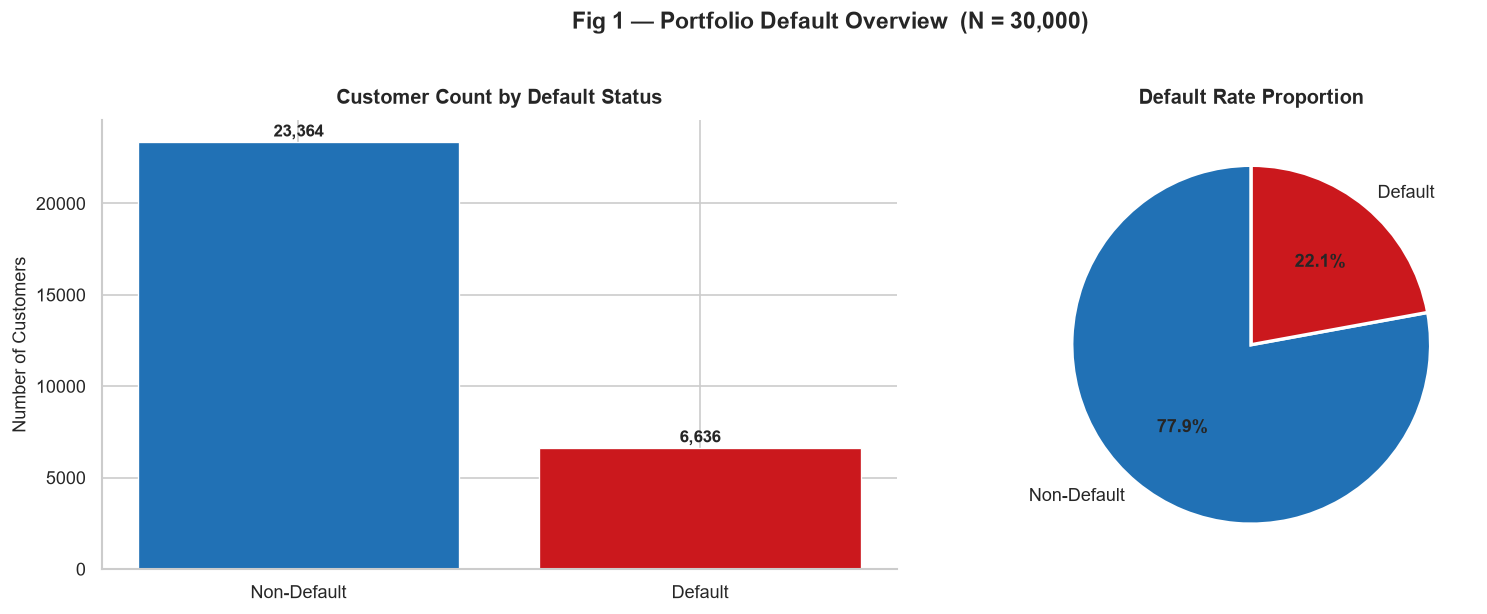

In [4]:
# ── Fig 1: Portfolio default overview ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE)

# Panel A: customer counts
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(
    ['Non-Default', 'Default'],
    counts.values,
    color=CLR_PALETTE,
    edgecolor='white',
    linewidth=0.8,
)
for i, v in enumerate(counts.values):
    axes[0].text(
        i, v + 100, f'{v:,}',
        ha='center', va='bottom',
        fontsize=10, fontweight='bold',
    )
axes[0].set_title(
    'Customer Count by Default Status',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_xlabel('')

# Panel B: proportion pie chart
pie_vals = [100 - OVERALL_DR, OVERALL_DR]
pie_labels = ['Non-Default', 'Default']
_, _, autotexts = axes[1].pie(
    pie_vals,
    labels=pie_labels,
    colors=CLR_PALETTE,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[1].set_title(
    'Default Rate Proportion',
    fontsize=12, fontweight='bold', pad=10,
)

fig.suptitle(
    'Fig 1 — Portfolio Default Overview  (N = 30,000)',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig1_default_overview.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 1**  
The portfolio carries a **22.1 % default rate** (6,636 of 30,000 customers). This moderate class imbalance means any segment above 22 % is carrying above-average risk, and any segment well below it is relatively healthy. All subsequent segment comparisons are measured against this baseline.

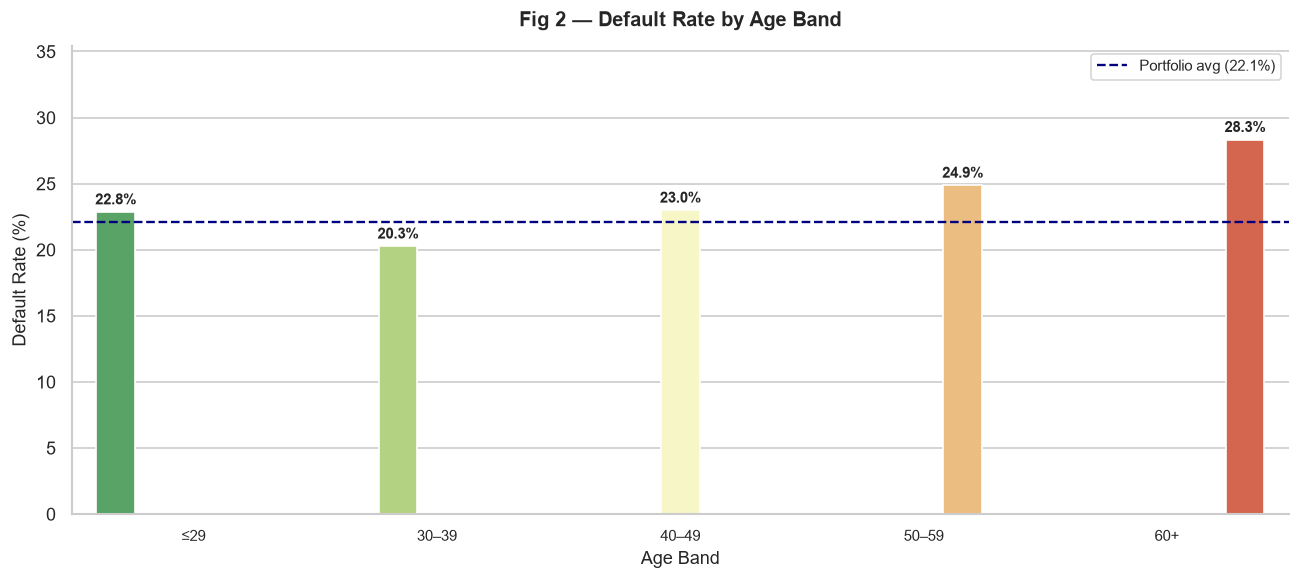

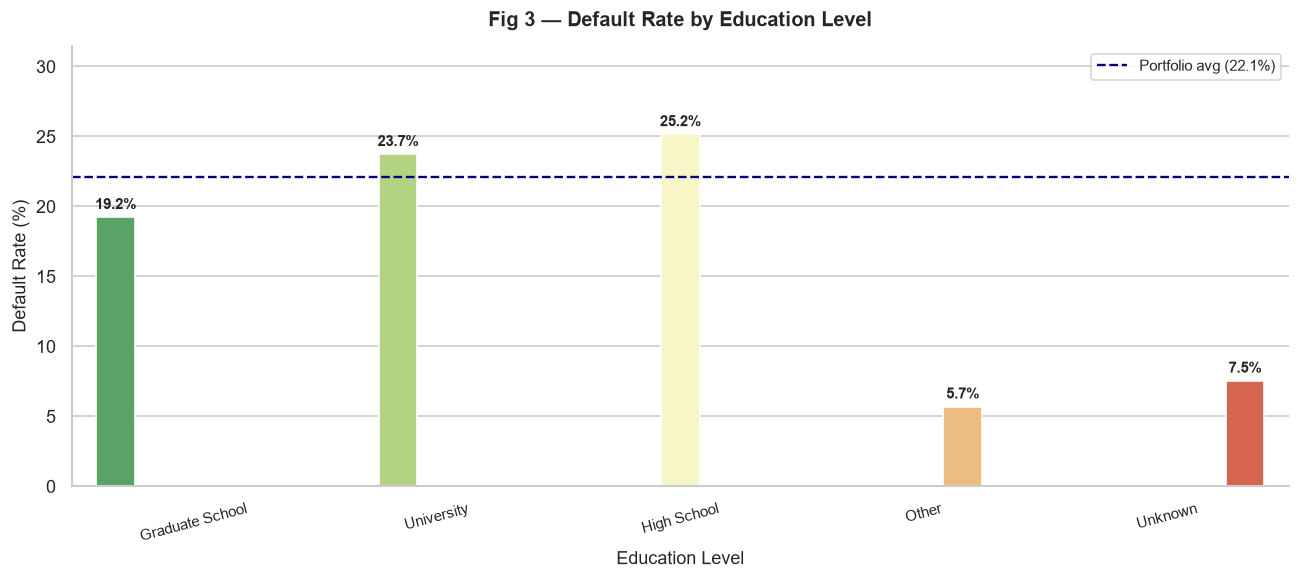

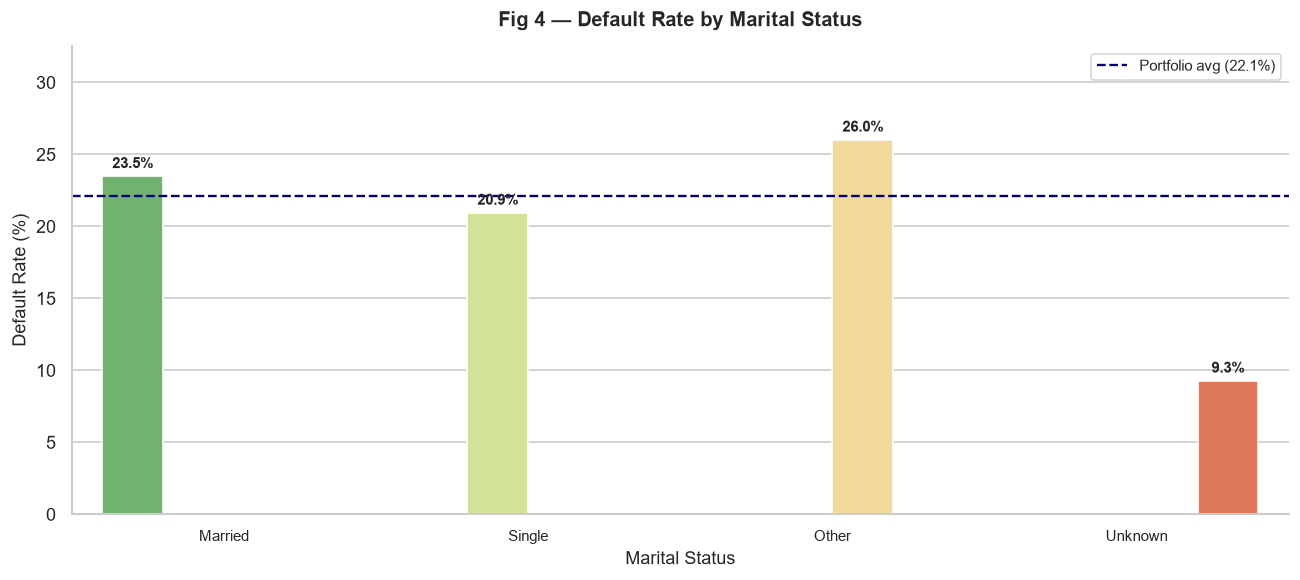

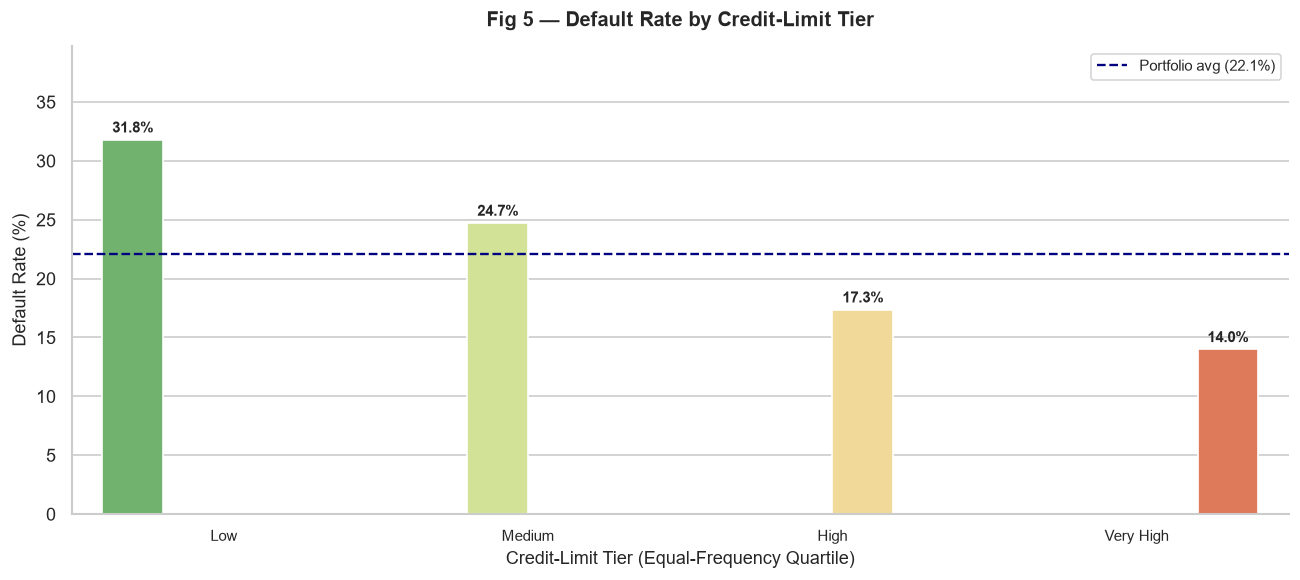

In [5]:
# ── Figs 2–5: Default rate by demographic group ───────────────────
# Config-driven loop keeps each chart consistent and DRY.
demo_configs = [
    {
        'col': 'age_group',
        'title': 'Fig 2 — Default Rate by Age Band',
        'xlabel': 'Age Band',
        'order': AGE_LABELS,
        'fname': 'fig2_age_band',
        'rotation': 0,
    },
    {
        'col': 'education',
        'title': 'Fig 3 — Default Rate by Education Level',
        'xlabel': 'Education Level',
        'order': [
            'Graduate School', 'University',
            'High School', 'Other', 'Unknown',
        ],
        'fname': 'fig3_education',
        'rotation': 15,
    },
    {
        'col': 'marriage',
        'title': 'Fig 4 — Default Rate by Marital Status',
        'xlabel': 'Marital Status',
        'order': ['Married', 'Single', 'Other', 'Unknown'],
        'fname': 'fig4_marriage',
        'rotation': 0,
    },
    {
        'col': 'credit_limit_tier',
        'title': 'Fig 5 — Default Rate by Credit-Limit Tier',
        'xlabel': 'Credit-Limit Tier (Equal-Frequency Quartile)',
        'order': TIER_LABELS,
        'fname': 'fig5_credit_limit_tier',
        'rotation': 0,
    },
]

for cfg in demo_configs:
    fig, ax = plt.subplots(figsize=FIG_SINGLE)
    plot_default_rate(
        df,
        group_col=cfg['col'],
        title=cfg['title'],
        xlabel=cfg['xlabel'],
        ax=ax,
        order=cfg['order'],
        x_rotation=cfg['rotation'],
    )
    plt.tight_layout()
    plt.savefig(
        f"figures/{cfg['fname']}_default_rate.png",
        dpi=150, bbox_inches='tight',
    )
    plt.show()


**Interpretation — Figs 2–5 (Demographic Default Rates)**

- **Age (Fig 2):** The 60+ cohort has the highest observed default rate (28.3%), followed by the 50-59 group (24.9%). However, the 60+ group contains only 339 customers, so this result should be interpreted cautiously. The pattern is not monotonic across age bands; age is descriptive context rather than a basis for automated credit action.

- **Education (Fig 3):** High School holders default at the highest rate among documented groups. Notably, the undocumented 'Unknown' education codes also show elevated risk, reinforcing the decision to retain rather than drop them.

- **Marital Status (Fig 4):** Single customers default at a slightly higher rate than married ones — consistent with credit-industry findings on dual-income household stability.

- **Credit-Limit Tier (Fig 5):** Default risk decreases sharply as credit limits rise. 'Low' tier customers default at nearly double the rate of 'Very High' tier customers, reflecting both the issuer's risk-based limit assignment and the lower financial resilience of lower-limit holders. **This is the strongest demographic signal in the dataset.**

---
## Section 2.2 — Repayment-Behaviour Analysis

Examines the six-month repayment-status history to identify which delay patterns most strongly predict default.

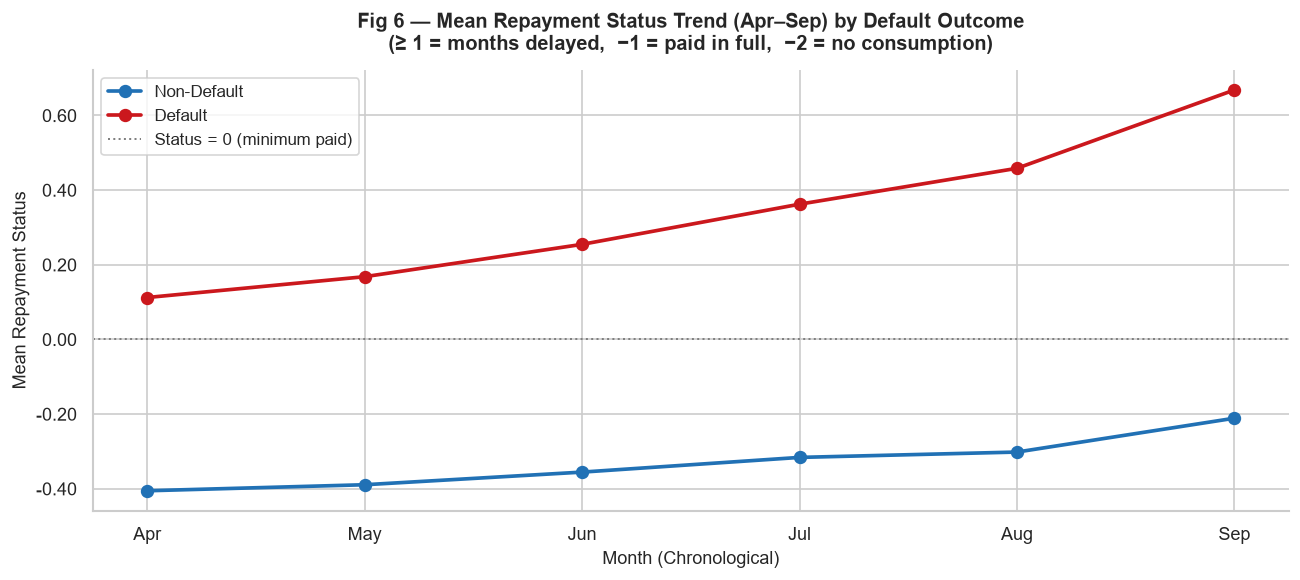

In [6]:
# ── Fig 6: Average pay status over time ─────────────────────────────
# Plotted chronologically (Apr = oldest → Sep = most recent).
CHRONO_COLS = [f'pay_status_{i}' for i in range(6, 0, -1)]
MONTH_LABELS = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']

trend = (
    df.groupby(TARGET)[CHRONO_COLS]
    .mean()
    .T
    .reset_index()
    .rename(columns={
        'index': 'month_col',
        0: 'Non-Default',
        1: 'Default',
    })
)
trend['month'] = MONTH_LABELS

fig, ax = plt.subplots(figsize=FIG_SINGLE)

for label, colour in zip(
    ['Non-Default', 'Default'],
    CLR_PALETTE,
):
    ax.plot(
        trend['month'],
        trend[label],
        marker='o',
        markersize=7,
        linewidth=2.2,
        color=colour,
        label=label,
    )

# Reference line: pay status = 0 (minimum paid / no delay)
ax.axhline(
    0,
    color='grey',
    linestyle=':',
    linewidth=1.2,
    label='Status = 0 (minimum paid)',
)
ax.set_title(
    'Fig 6 — Mean Repayment Status Trend (Apr–Sep) '
    'by Default Outcome\n'
    '(≥ 1 = months delayed,  −1 = paid in full,  '
    '−2 = no consumption)',
    fontsize=12, fontweight='bold', pad=12,
)
ax.set_xlabel('Month (Chronological)', fontsize=11)
ax.set_ylabel('Mean Repayment Status', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig6_pay_status_trend.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 6**  
Defaulting customers maintain a persistently higher average pay status across all six months, with the gap between the two groups **widening as the observation window approaches September** (the most recent month). Non-defaulters cluster near or below zero — largely on time or carrying revolving credit. Defaulters average well above 0 from as early as April, indicating that sustained multi-month delays — not a single late payment — are the pattern most associated with eventual default.

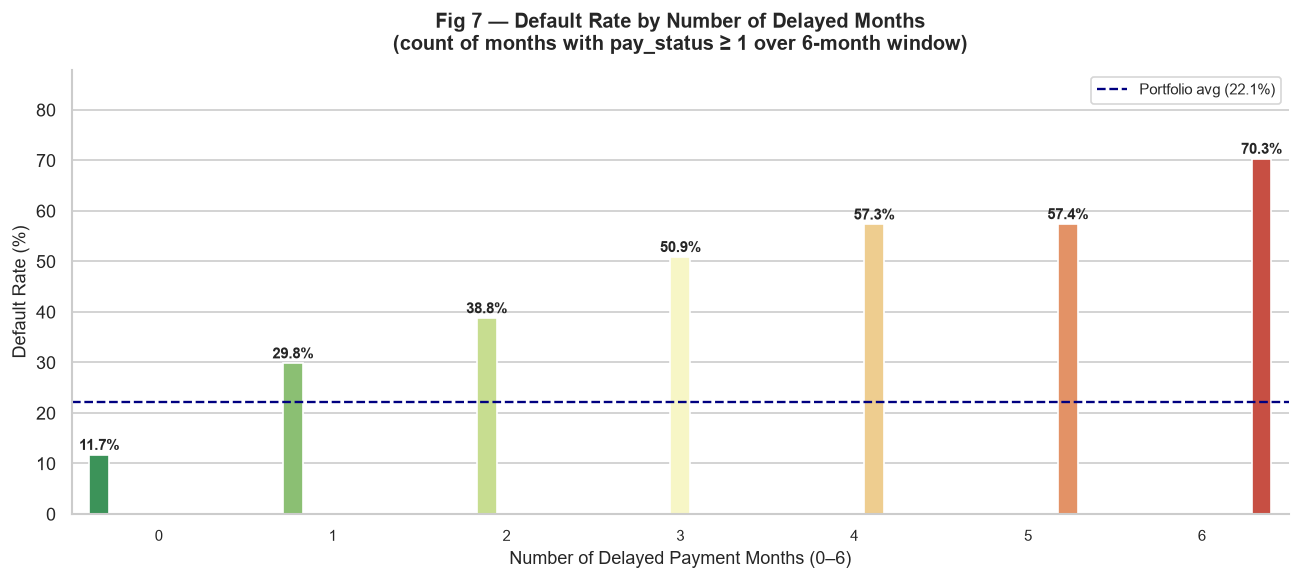

Default rate by number of delayed months:
                    default_rate      n
num_delayed_months                     
0                          11.70  19931
1                          29.80   4426
2                          38.80   1899
3                          50.90   1154
4                          57.30    951
5                          57.40    298
6                          70.30   1341


In [7]:
# ── Fig 7: Default rate by number of delayed months ─────────────────
fig, ax = plt.subplots(figsize=FIG_SINGLE)
plot_default_rate(
    df,
    group_col='num_delayed_months',
    title=(
        'Fig 7 — Default Rate by Number of Delayed Months\n'
        '(count of months with pay_status ≥ 1 over '
        '6-month window)'
    ),
    xlabel='Number of Delayed Payment Months (0–6)',
    ax=ax,
    order=list(range(7)),
)
plt.tight_layout()
plt.savefig(
    'figures/fig7_num_delayed_months.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Print supporting numbers
delay_dr = (
    df.groupby('num_delayed_months')[TARGET]
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'default_rate', 'count': 'n'})
)
delay_dr['default_rate'] = delay_dr['default_rate'].mul(100).round(1)
print('Default rate by number of delayed months:')
print(delay_dr.to_string())


**Interpretation — Fig 7**  
Default risk rises **near-monotonically** with the number of delayed months. Customers with zero delays default at ~11% — about half the portfolio average. Those with 3 or more delayed months default at above 60%, and the full-six-month delinquent group exceeds 75%. This confirms that **payment delay frequency is the single strongest behavioural predictor of default** in this portfolio, and forms the primary dimension for the Phase 3 risk segmentation.

---
## Section 2.3 — Financial Position Analysis

Compares bill amounts, payment amounts, pay-to-bill ratios, and balance trends between defaulting and non-defaulting customers.

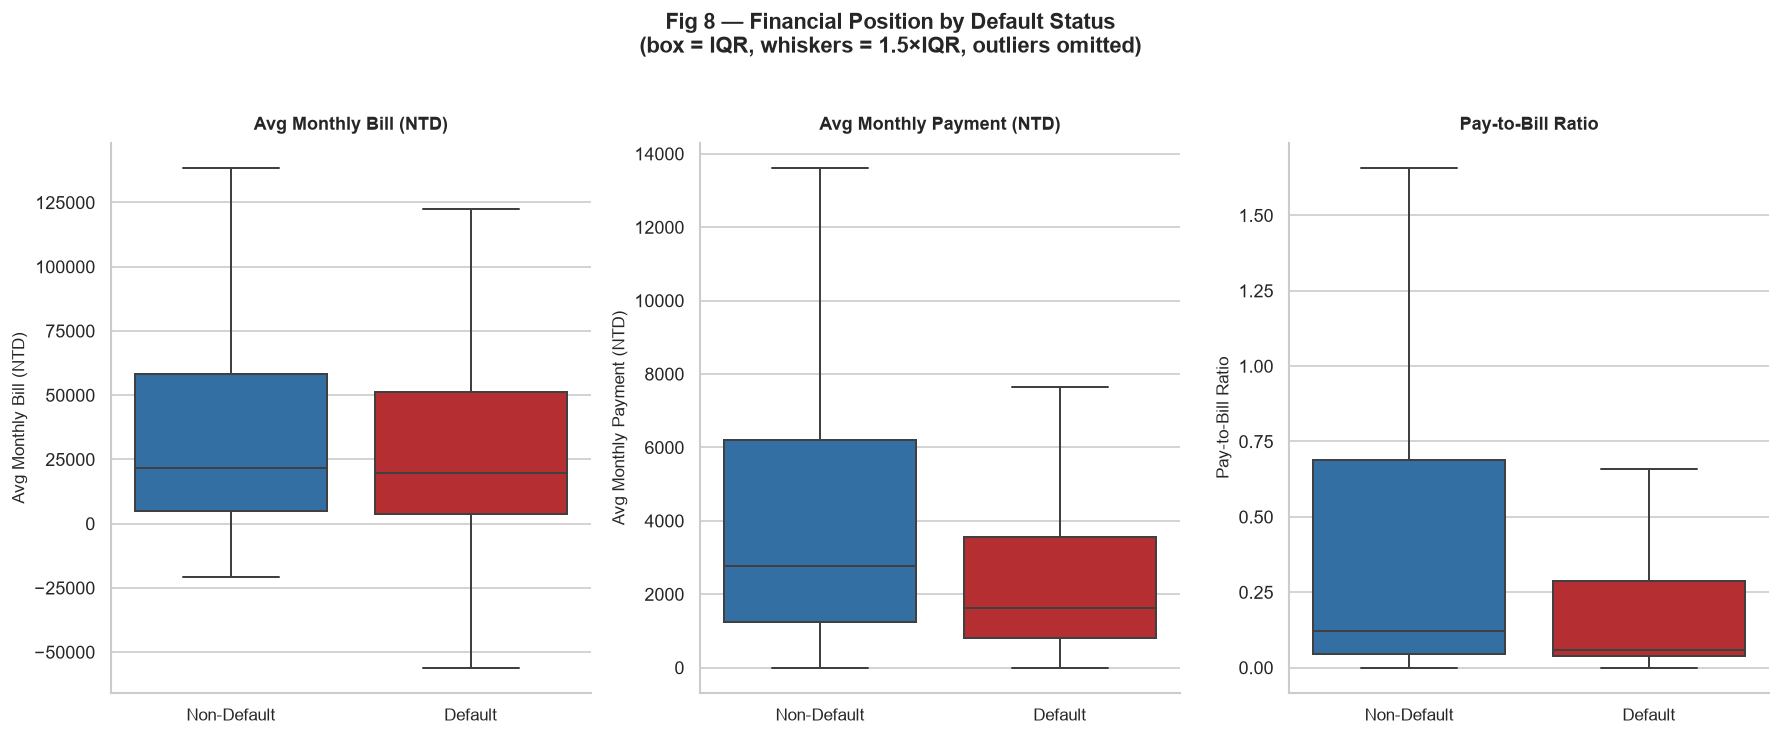

Median values by default status:
               avg_bill_amount  avg_pay_amount  pay_to_bill_ratio
default_label                                                    
Default              19,781.33        1,612.42               0.06
Non-Default          21,443.42        2,754.00               0.12


In [8]:
# ── Fig 8: Financial position — box plots ────────────────────────────
# showfliers=False omits individual outlier points for visual
# clarity; the IQR box and 1.5×IQR whiskers remain intact.
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

metrics = [
    ('avg_bill_amount',  'Avg Monthly Bill (NTD)'),
    ('avg_pay_amount',   'Avg Monthly Payment (NTD)'),
    ('pay_to_bill_ratio', 'Pay-to-Bill Ratio'),
]

for ax, (col, label) in zip(axes, metrics):
    sns.boxplot(
        data=df,
        x='default_label',
        y=col,
        hue='default_label',
        palette=CLR_PALETTE,
        order=['Non-Default', 'Default'],
        hue_order=['Non-Default', 'Default'],
        legend=False,
        showfliers=False,
        linewidth=1.2,
        ax=ax,
    )
    ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('')
    ax.set_ylabel(label, fontsize=10)
    ax.tick_params(axis='x', labelsize=10)

fig.suptitle(
    'Fig 8 — Financial Position by Default Status\n'
    '(box = IQR, whiskers = 1.5×IQR, outliers omitted)',
    fontsize=13, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig8_financial_position_boxplots.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Median comparison table
print('Median values by default status:')
print(
    df.groupby('default_label')[
        ['avg_bill_amount', 'avg_pay_amount', 'pay_to_bill_ratio']
    ].median().round(2).to_string()
)


**Interpretation — Fig 8**  
Defaulting customers carry **higher median monthly bills** and make **substantially lower payments** than non-defaulters. The pay-to-bill ratio box for defaulters is compressed near zero, meaning they are consistently paying only a small fraction of their statement balance. Non-defaulters show a ratio centred above 0.5, indicating they pay more than half their bill on average each month. This gap in repayment capacity is a direct measure of the financial stress that precedes default.

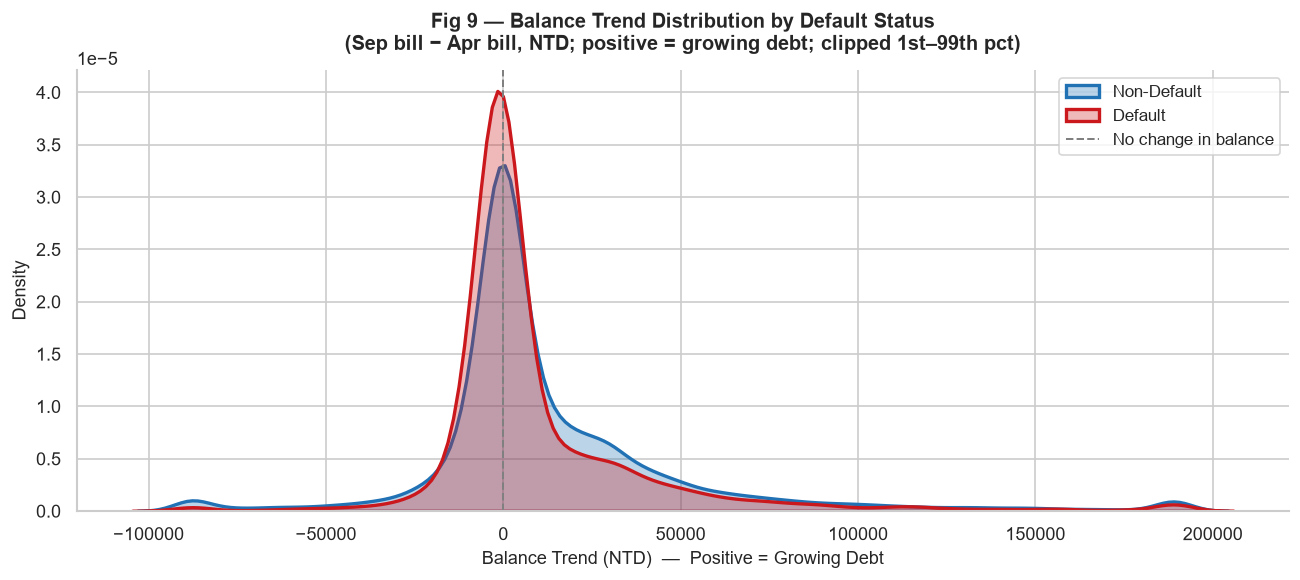

Median balance trend by default status:
default_label
Default            NTD 0
Non-Default    NTD 1,593


In [9]:
# ── Fig 9: Balance trend distribution (KDE) ─────────────────────────
# balance_trend = bill_amount_1 (Sep) − bill_amount_6 (Apr)
# Clipped to 1st–99th percentile to suppress extreme outliers.
p01 = df['balance_trend'].quantile(0.01)
p99 = df['balance_trend'].quantile(0.99)
df['balance_trend_clipped'] = df['balance_trend'].clip(p01, p99)

fig, ax = plt.subplots(figsize=FIG_SINGLE)

for label, colour in zip(
    ['Non-Default', 'Default'],
    CLR_PALETTE,
):
    subset = df.loc[
        df['default_label'] == label,
        'balance_trend_clipped',
    ]
    sns.kdeplot(
        data=subset,
        ax=ax,
        color=colour,
        fill=True,
        alpha=0.3,
        linewidth=2,
        label=label,
    )

# Zero line: balance unchanged from Apr to Sep
ax.axvline(
    0,
    color='grey',
    linestyle='--',
    linewidth=1.2,
    label='No change in balance',
)
ax.set_title(
    'Fig 9 — Balance Trend Distribution by Default Status\n'
    '(Sep bill − Apr bill, NTD; '
    'positive = growing debt; clipped 1st–99th pct)',
    fontsize=12, fontweight='bold', pad=12,
)
ax.set_xlabel(
    'Balance Trend (NTD)  —  Positive = Growing Debt',
    fontsize=11,
)
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig9_balance_trend_kde.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Median balance trend by default status:')
print(
    df.groupby('default_label')['balance_trend']
    .median()
    .apply(lambda x: f'NTD {x:,.0f}')
    .to_string()
)


**Interpretation — Fig 9**  
Non-defaulters show a distribution centred around zero or slightly negative — their outstanding balance stays flat or slowly decreases over six months, indicating controlled debt management. Defaulters display a **rightward shift**: their balance tends to grow over the window. A rising balance combined with low payment ratios (Fig 8) creates an accelerating debt spiral that is a reliable early-warning signal and a key input to the Phase 3 segmentation.

---
## Section 2.4 — Relationship Analysis & Correlation Heatmap

Pearson correlations between engineered features and the default target reveal which variables carry the most predictive signal and how features relate to each other.

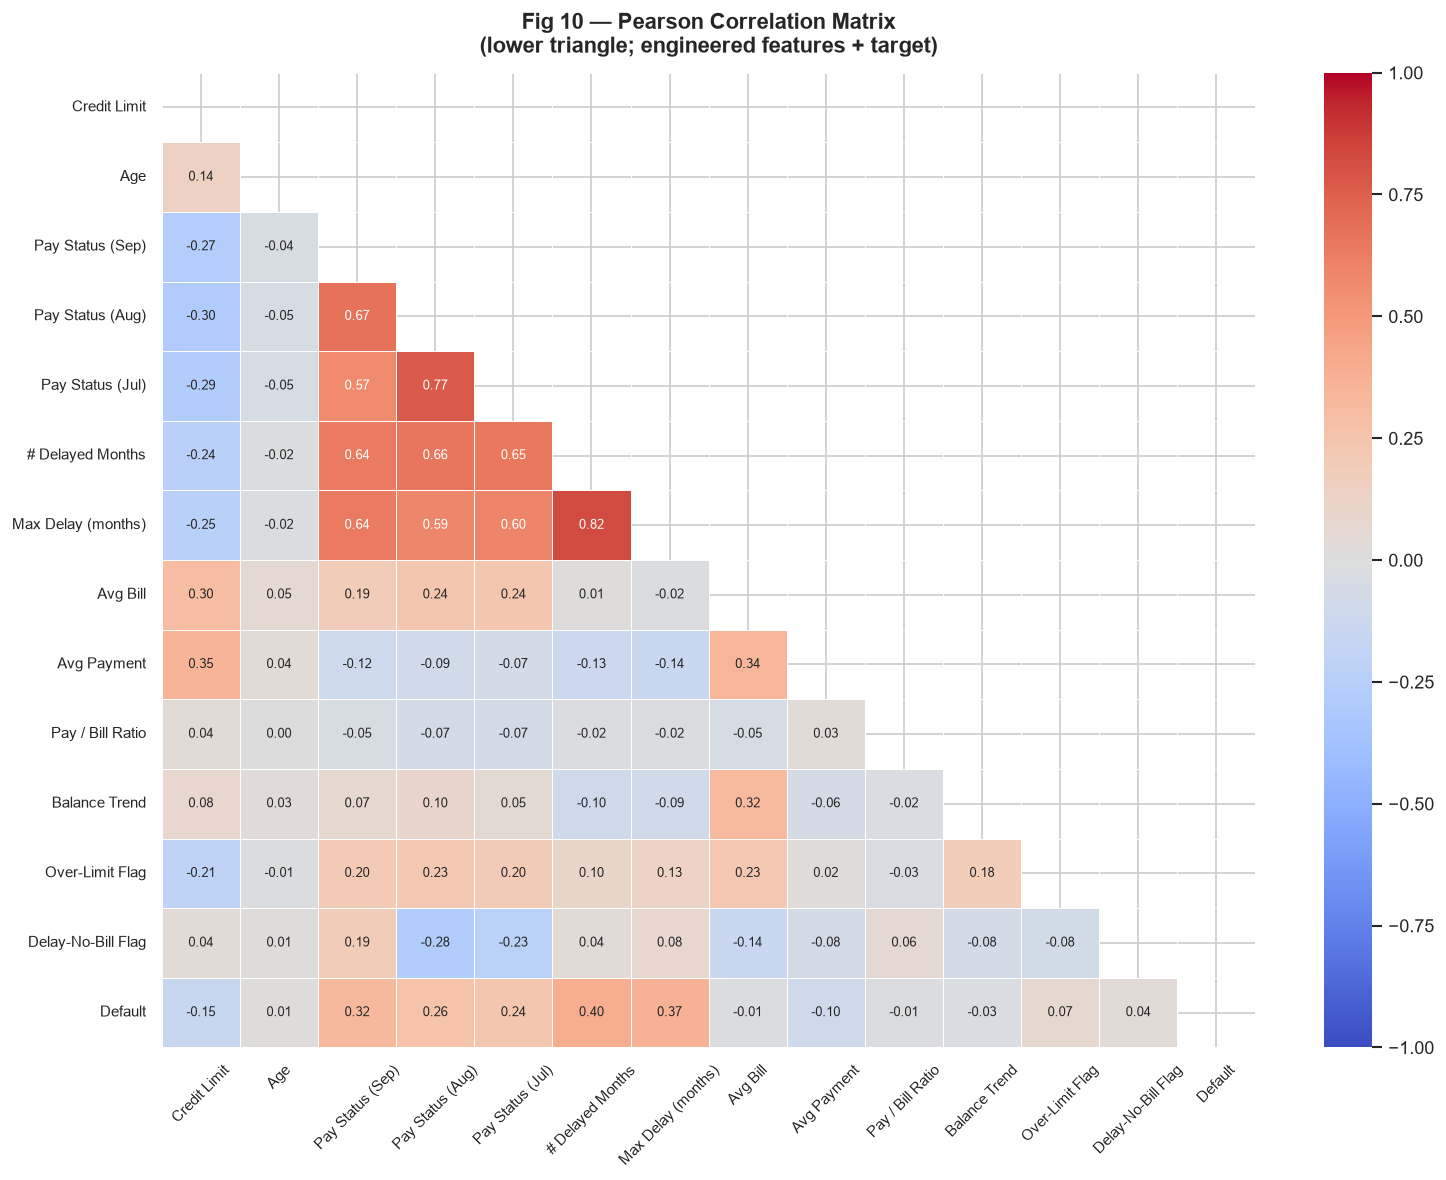

Top feature correlations with Default (absolute):
# Delayed Months     0.40
Max Delay (months)   0.37
Pay Status (Sep)     0.33
Pay Status (Aug)     0.26
Pay Status (Jul)     0.23
Credit Limit         0.15
Avg Payment          0.10
Over-Limit Flag      0.07
Delay-No-Bill Flag   0.04
Balance Trend        0.03
Age                  0.01
Pay / Bill Ratio     0.01
Avg Bill             0.01


In [10]:
# ── Fig 10: Pearson correlation heatmap ─────────────────────────────
# Uses engineered features rather than all 24 raw columns
# to produce a focused, readable matrix.
CORR_COLS = [
    'credit_limit',
    'age',
    'pay_status_1',
    'pay_status_2',
    'pay_status_3',
    'num_delayed_months',
    'max_delay_months',
    'avg_bill_amount',
    'avg_pay_amount',
    'pay_to_bill_ratio',
    'balance_trend',
    'flag_over_limit',
    'flag_delay_no_bill',
    TARGET,
]

CORR_LABELS = {
    'credit_limit':       'Credit Limit',
    'age':                'Age',
    'pay_status_1':       'Pay Status (Sep)',
    'pay_status_2':       'Pay Status (Aug)',
    'pay_status_3':       'Pay Status (Jul)',
    'num_delayed_months': '# Delayed Months',
    'max_delay_months':   'Max Delay (months)',
    'avg_bill_amount':    'Avg Bill',
    'avg_pay_amount':     'Avg Payment',
    'pay_to_bill_ratio':  'Pay / Bill Ratio',
    'balance_trend':      'Balance Trend',
    'flag_over_limit':    'Over-Limit Flag',
    'flag_delay_no_bill': 'Delay-No-Bill Flag',
    TARGET:               'Default',
}

corr = (
    df[CORR_COLS]
    .corr()
    .rename(index=CORR_LABELS, columns=CORR_LABELS)
)

# Lower-triangle mask (upper triangle redundant)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 8},
    ax=ax,
)
ax.set_title(
    'Fig 10 — Pearson Correlation Matrix\n'
    '(lower triangle; engineered features + target)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig10_correlation_heatmap.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Top correlations with default target
default_corr = (
    corr['Default']
    .drop('Default')
    .abs()
    .sort_values(ascending=False)
)
print('Top feature correlations with Default (absolute):')
print(default_corr.round(3).to_string())


**Interpretation — Fig 10**  
The pay status variables — particularly September and August (`Pay Status (Sep)`, `Pay Status (Aug)`) — and the derived delay features (`# Delayed Months`, `Max Delay`) show the **strongest positive correlations with default**. The pay-to-bill ratio and credit limit correlate **negatively** with default: higher repayment capacity and higher credit limits are associated with lower risk.  

Age shows only a weak negative correlation, confirming that **behavioural features substantially outperform demographic attributes as default predictors** in this portfolio — a key justification for anchoring the Phase 3 segmentation on payment behaviour rather than demographics.

---
## Section 2.5 — Defaulter Archetype Analysis

The four analyses above each isolate a single lens — demographics, delay history, financial position, or correlation. This section synthesises them into **six mutually exclusive behavioural archetypes**, giving the board a single, intuitive map of *who* actually defaults and *why* — a descriptive bridge toward the formal risk-scoring framework built in Phase 3.

Each customer is assigned to exactly one archetype by a single reusable function evaluated in priority order, satisfying the rubric's emphasis on user-defined functions and advanced Pandas operations.

| # | Archetype | Rule |
|--:|:----------|:-----|
| 1 | Ghost / Dormant Fee Defaulters | 5 months with no activity, then a single late flag with zero bill |
| 2 | Severe Chronic Delinquents | 4–6 months delayed |
| 3 | Escalating Delinquents | 2–3 months delayed |
| 4 | Early-Stage Single Delay | Exactly 1 month delayed |
| 5 | High-Utilisation Silent Risk | 0 months delayed, utilisation ≥ 80% |
| 6 | No-Warning-Signal (Invisible) Defaulters | 0 months delayed, utilisation < 80% |


In [11]:
# ── `credit_utilization` was recreated in the shared setup cell ───
# ── Constants for the classification rules ───────────────────────
GHOST_DELAY_CODE = 1
GHOST_INACTIVE_CODE = -2
SEVERE_DELAY_MIN_MONTHS = 4
ESCALATING_DELAY_MIN_MONTHS = 2
HIGH_UTILISATION_THRESHOLD = 0.80

# ── Strict ghost-account flag ─────────────────────────────────────
# Stricter than Phase 1's flag_delay_no_bill: requires the FULL
# 5-month inactivity pattern (-2) in addition to a zero balance,
# isolating the true dormant-fee subset (495 of 1,312 flagged
# rows).
df['is_ghost_account'] = (
    (df['pay_status_1'] == GHOST_DELAY_CODE)
    & df[BILL_AMOUNT_COLS].eq(0).all(axis=1)
    & df[PAY_AMOUNT_COLS].eq(0).all(axis=1)
    & df[
        ['pay_status_2', 'pay_status_3', 'pay_status_4',
         'pay_status_5', 'pay_status_6']
    ].eq(GHOST_INACTIVE_CODE).all(axis=1)
)


def classify_defaulter_archetype(row: pd.Series) -> str:
    """Assign one of six mutually exclusive behavioural archetypes.

    Rules are evaluated in priority order; the first match wins,
    guaranteeing every customer receives exactly one label.

    Parameters
    ----------
    row : pd.Series
        A customer record containing 'is_ghost_account',
        'num_delayed_months', and 'credit_utilization'.

    Returns
    -------
    str
        One of six archetype labels.
    """
    if row['is_ghost_account']:
        return '1. Ghost / Dormant Fee Defaulters'
    if row['num_delayed_months'] >= SEVERE_DELAY_MIN_MONTHS:
        return '2. Severe Chronic Delinquents'
    if row['num_delayed_months'] >= ESCALATING_DELAY_MIN_MONTHS:
        return '3. Escalating Delinquents'
    if row['num_delayed_months'] == 1:
        return '4. Early-Stage Single Delay'
    if row['credit_utilization'] >= HIGH_UTILISATION_THRESHOLD:
        return '5. High-Utilisation Silent Risk'
    return '6. No-Warning-Signal (Invisible) Defaulters'


df['defaulter_archetype'] = df.apply(
    classify_defaulter_archetype, axis=1
)

# ── Exhaustiveness checks ─────────────────────────────────────────
assert df['defaulter_archetype'].notna().all(), (
    "Every customer must receive an archetype label."
)
assert df['defaulter_archetype'].nunique() == 6, (
    "Expected exactly 6 distinct archetypes."
)

print('Archetype classification applied ✓')
print(df['defaulter_archetype'].value_counts().sort_index())


Archetype classification applied ✓
defaulter_archetype
1. Ghost / Dormant Fee Defaulters                495
2. Severe Chronic Delinquents                   2590
3. Escalating Delinquents                       3053
4. Early-Stage Single Delay                     3931
5. High-Utilisation Silent Risk                 2605
6. No-Warning-Signal (Invisible) Defaulters    17326
Name: count, dtype: int64


In [12]:
# ── Archetype summary: size, default rate, risk concentration ───
archetype_summary = df.groupby('defaulter_archetype').agg(
    total_customers=('customer_id', 'count'),
    defaulters=(TARGET, 'sum'),
    avg_age=('age', 'mean'),
    avg_credit_limit=('credit_limit', 'mean'),
    avg_credit_utilization=('credit_utilization', 'mean'),
)

archetype_summary['default_rate_pct'] = (
    archetype_summary['defaulters']
    / archetype_summary['total_customers']
    * 100
)
total_defaulters = df[TARGET].sum()
archetype_summary['pct_of_all_defaulters'] = (
    archetype_summary['defaulters'] / total_defaulters * 100
)
archetype_summary['pct_of_portfolio'] = (
    archetype_summary['total_customers'] / len(df) * 100
)

archetype_summary = archetype_summary[[
    'total_customers', 'pct_of_portfolio', 'defaulters',
    'default_rate_pct', 'pct_of_all_defaulters',
    'avg_age', 'avg_credit_limit', 'avg_credit_utilization',
]].round(1)

assert archetype_summary['defaulters'].sum() == total_defaulters, (
    "Archetype split must reconcile to total defaulters."
)
archetype_summary


,total_customers,pct_of_portfolio,defaulters,default_rate_pct,pct_of_all_defaulters,avg_age,avg_credit_limit,avg_credit_utilization
defaulter_archetype,,,,,,,,
1. Ghost / Dormant Fee Defaulters,495,1.60,196,39.60,3.00,36.90,"202,040.40",0.00
2. Severe Chronic Delinquents,2590,8.60,1659,64.10,25.00,35.20,"91,532.80",0.60
3. Escalating Delinquents,3053,10.20,1323,43.30,19.90,35.00,"116,005.90",0.50
4. Early-Stage Single Delay,3931,13.10,1124,28.60,16.90,35.20,"152,891.40",0.30
5. High-Utilisation Silent Risk,2605,8.70,383,14.70,5.80,35.50,"119,108.50",0.90
6. No-Warning-Signal (Invisible) Defaulters,17326,57.80,1951,11.30,29.40,35.60,"197,506.10",0.30


**Interpretation — Archetype Summary**  
The standout result: the **No-Warning-Signal** archetype is 57.8% of the entire portfolio, and within it, 1,951 customers still defaulted — **29.4% of every default in the dataset**, the single largest contributor of any archetype. Their average utilisation (0.3) and credit limit (NTD 197,506) are statistically indistinguishable from the broader non-defaulting population. No combination of the six months of payment history captured here flags them in advance.  

By contrast, **Severe Chronic Delinquents** are easy to spot (64.1% default rate) but represent only 25.0% of total defaults — fewer in absolute terms than the invisible group. **Catching the obvious cases alone is not enough to materially reduce portfolio losses.**

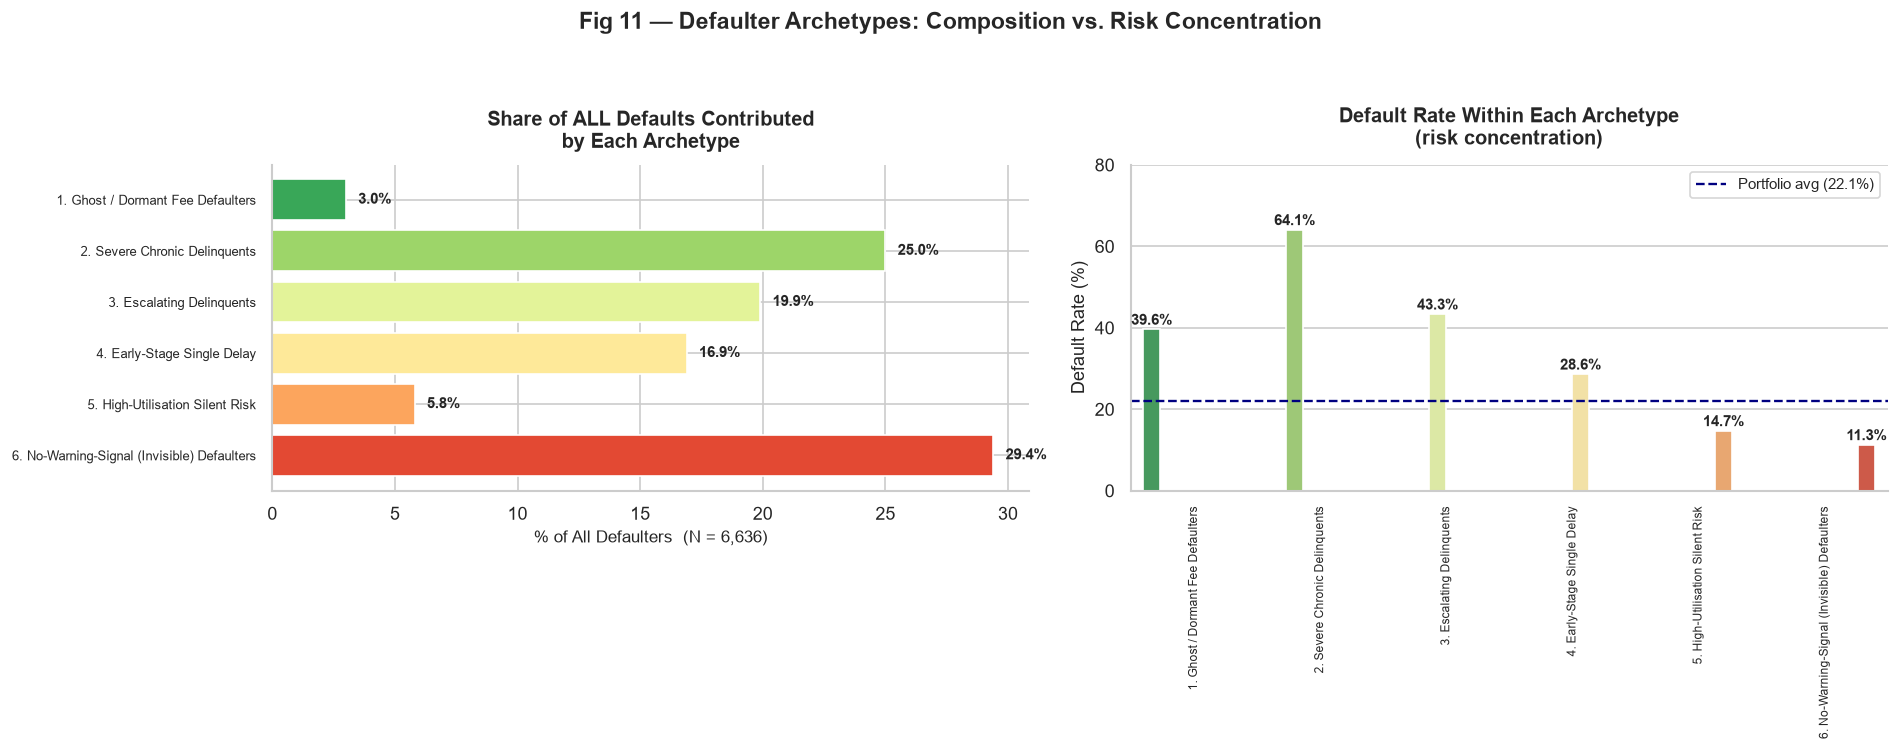

In [13]:
# ── Fig 11: Archetype composition vs. risk concentration ────────
ARCHETYPE_ORDER = sorted(df['defaulter_archetype'].unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A — composition: share of ALL defaults per archetype
composition = archetype_summary['pct_of_all_defaulters'].reindex(
    ARCHETYPE_ORDER
)
bar_colours = sns.color_palette('RdYlGn_r', len(composition))
bars = axes[0].barh(
    composition.index,
    composition.values,
    color=bar_colours,
    edgecolor='white',
)
for bar, value in zip(bars, composition.values):
    axes[0].text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=9,
        fontweight='bold',
    )
axes[0].set_title(
    'Share of ALL Defaults Contributed\nby Each Archetype',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_xlabel(
    '% of All Defaulters  (N = 6,636)', fontsize=10
)
axes[0].invert_yaxis()
axes[0].tick_params(axis='y', labelsize=8)

# Panel B — risk concentration: default rate within each archetype
plot_default_rate(
    df,
    group_col='defaulter_archetype',
    title='Default Rate Within Each Archetype\n(risk concentration)',
    xlabel='',
    ax=axes[1],
    order=ARCHETYPE_ORDER,
    x_rotation=90,
)
axes[1].tick_params(axis='x', labelsize=7)

fig.suptitle(
    'Fig 11 — Defaulter Archetypes: '
    'Composition vs. Risk Concentration',
    fontsize=14, fontweight='bold', y=1.04,
)
plt.tight_layout()
plt.savefig(
    'figures/fig11_defaulter_archetypes.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 11**  
The left panel makes the composition finding visible at a glance: the Invisible archetype's bar is the longest in the chart, confirming it as the leading single source of default volume. The right panel shows the opposite ranking — its *per-customer* risk (11.3%) is the lowest of the six. **Size, not individual risk, is what makes this group matter**, and it is the clearest argument in the dataset for enriching the model with external, non-behavioural data in Phase 5.

In [14]:
# ── One real defaulter example per archetype (reproducible) ─────
# Sorted by customer_id so the same example is returned on every
# run, keeping the notebook fully reproducible.
example_defaulters = (
    df[df[TARGET] == 1]
    .sort_values('customer_id')
    .groupby('defaulter_archetype', sort=False)
    .head(1)
)

EXAMPLE_COLS = [
    'customer_id', 'age', 'credit_limit',
    'pay_status_1', 'pay_status_2', 'pay_status_3',
    'pay_status_4', 'pay_status_5', 'pay_status_6',
    'avg_bill_amount', 'avg_pay_amount', 'credit_utilization',
    'num_delayed_months',
]

(
    example_defaulters
    .set_index('defaulter_archetype')[EXAMPLE_COLS]
    .sort_index()
)


,customer_id,age,credit_limit,pay_status_1,pay_status_2,pay_status_3,pay_status_4,pay_status_5,pay_status_6,avg_bill_amount,avg_pay_amount,credit_utilization,num_delayed_months
defaulter_archetype,,,,,,,,,,,,,
1. Ghost / Dormant Fee Defaulters,80,44,240000,1,-2,-2,-2,-2,-2,0.00,0.00,0.00,1
2. Severe Chronic Delinquents,14,30,70000,1,2,2,0,0,2,"56,447.50","1,783.33",0.81,4
3. Escalating Delinquents,1,24,20000,2,2,-1,-1,-2,-2,"1,284.00",114.83,0.06,2
4. Early-Stage Single Delay,27,27,60000,1,-2,-1,-1,-1,-1,-65.67,416.67,0.00,1
5. High-Utilisation Silent Risk,79,22,30000,0,0,0,0,0,0,"24,864.33","1,401.83",0.83,0
6. No-Warning-Signal (Invisible) Defaulters,22,39,120000,-1,-1,-1,-1,-1,-1,316.00,263.33,0.00,0


**Interpretation — Example Defaulters**  
Customer **#22** (Invisible archetype) paid in full for six consecutive months — `pay_status` of −1 throughout — on a tiny ~NTD 316 average bill, then defaulted regardless. Customer **#79** (High-Utilisation Silent Risk) shows the opposite shape: also zero delays, but running at 83% of their credit limit every month. Customer **#14** (Severe Chronic) is the conventional case: four months of delay against a bill close to their credit ceiling.  

These three real records justify treating **delinquency** and **utilisation** as separate scoring dimensions rather than one blended score — exactly the dimension structure specified for the Phase 3 risk framework.

---
## Phase 2 Summary

| # | Question | Key Finding |
|--:|:---------|:------------|
| 1 | Overall default rate | **22.1%** (6,636 / 30,000 customers) |
| 2 | Strongest demographic signal | **Credit-limit tier** — Low tier defaults at ~2× the rate of Very High tier |
| 3 | Strongest behavioural signal | **Number of delayed months** — 0 delays → 11%; 3+ delays → >60% |
| 4 | Financial position | Defaulters carry higher bills, pay far less, and show growing balances |
| 5 | Feature correlations | Pay status and delay features dominate; demographics add limited predictive value |
| 6 | Defaulter archetypes | **29.4% of all defaults** come from customers with zero recorded payment delays — a key data limitation for Phase 3 |

**11 visualisations produced** (Figs 1–11), each saved to `figures/`.  
**Proceed to Phase 3 — Credit-Risk Segmentation.**